# 08 — Global-model robustness and specification audit

This notebook challenges the global ridge benchmark before any separate models are considered. It asks whether the apparent global-model performance depends on an arbitrary history window, ridge penalty, training sample, feature specification, target formulation, or weighting objective.

The audit covers:

1. expanding versus rolling training histories;
2. nested validation of the ridge penalty;
3. training-sample size and seed sensitivity;
4. economically motivated feature-group add/drop experiments;
5. coefficient sign and stability review;
6. alternative target formulations and weighting objectives;
7. residual calibration and extreme-auction behavior;
8. distribution drift and a shuffled-target placebo.

All test results remain out of time. No feature is removed from the master panel.

In [1]:
from pathlib import Path
import sys
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 160)
pd.set_option("display.max_rows", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 7), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")
sys.path.insert(0, str(PROJECT_ROOT))

from notebooks.modeling_utils import (
    fit_preprocessor, apply_preprocessor, fit_ridge, predict_ridge, forecast_metrics
)

PANEL = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "enriched_daily_panel.parquet"
CATALOG = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "approved_enriched_daily_features.csv"
VALIDATION = PROJECT_ROOT / "outputs" / "eda" / "06_feature_validation" / "feature_validation_and_roles.csv"
BASELINE_DIR = PROJECT_ROOT / "outputs" / "eda" / "07_temporal_baselines"
OUT = PROJECT_ROOT / "outputs" / "eda" / "08_global_robustness"
OUT.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query, params=None):
    return con.execute(query, params or []).df()

catalog = pd.read_csv(CATALOG)
feature_validation = pd.read_csv(VALIDATION)
FEATURES = catalog["variable"].tolist()
FEATURE_GROUPS = catalog.groupby("group")["variable"].apply(list).to_dict()
TEST_YEARS = [2022, 2023, 2024, 2025]
print(f"Features: {len(FEATURES)} across {len(FEATURE_GROUPS)} economic groups")
display(catalog.groupby("group").size().rename("features").to_frame())

Features: 99 across 8 economic groups


,features
group,
Auction history,19
Calendar,23
Liquidity,16
Market state,8
Returns and price,11
Sector state,8
Security and corporate actions,4
Size and history,10


## Shared feature and query definitions

In [2]:
BOOLEAN_FEATURES = [
    "auction_spike_lag1", "is_monday", "is_friday",
    "is_first_trading_day_month", "is_last_trading_day_month",
    "is_last_3_trading_days_month", "is_last_5_trading_days_month",
    "is_last_trading_day_quarter", "is_last_3_trading_days_quarter",
    "is_last_5_trading_days_quarter", "is_last_trading_day_year",
    "monthly_options_expiry", "quarterly_options_expiry",
    "after_long_market_gap", "before_long_market_gap", "is_early_close",
    "early_close_month_end_window", "expiry_month_end_window",
    "lag1_dividend_flag", "lag1_distribution_flag", "lag1_price_adjustment_flag",
]
CATEGORICAL_FEATURES = ["month", "day_of_week", "ff12_code", "size_decile", "liquidity_decile"]
CONTINUOUS_FEATURES = [f for f in FEATURES if f not in BOOLEAN_FEATURES and f not in CATEGORICAL_FEATURES]
CONTEXT = [
    "date", "permno", "auction_volume", "log1p_auction_volume",
    "median20_auction_volume", "avg20_daily_volume",
]
QUERY_COLUMNS = list(dict.fromkeys(CONTEXT + FEATURES))
QUOTED_COLUMNS = ", ".join(f'"{c}"' for c in QUERY_COLUMNS)

def load_period(start_date, end_date, sample_rows, seed):
    sample_clause = f"USING SAMPLE {sample_rows} ROWS (reservoir, {seed})" if sample_rows else ""
    return sql(f"""
        SELECT * FROM (
            SELECT {QUOTED_COLUMNS}
            FROM read_parquet('{PANEL}')
            WHERE eligible_target
              AND date >= DATE '{start_date}' AND date < DATE '{end_date}'
        ) {sample_clause}
    """)

def start_for_window(end_year, window):
    if window == "expanding":
        return "2015-01-01"
    years = int(window.replace("rolling", ""))
    return f"{end_year - years}-01-01"

def matrix_columns_for_sources(params, allowed_sources):
    allowed = set(allowed_sources)
    return np.array([source in allowed for source in params["output_sources"]])

def fit_predict_log(x_train, y_train_log, x_test, strength, weights=None):
    coef = fit_ridge(x_train, y_train_log, strength, weights)
    prediction = predict_ridge(x_test, coef)
    lo, hi = np.quantile(y_train_log[np.isfinite(y_train_log)], [0.001, 0.999])
    return np.clip(prediction, lo, hi), coef

def metric_row(y_raw, prediction_raw, **labels):
    return {**labels, **forecast_metrics(y_raw, prediction_raw)}

## Window sensitivity with nested penalty selection

For every test year and history window, the immediately preceding year is used only to choose the ridge penalty. The model is then refitted through the end of that year and scored on the untouched test year.

Compared histories:

- expanding history beginning in 2015;
- rolling five-year history;
- rolling three-year history.

In [3]:
WINDOWS = ["expanding", "rolling5", "rolling3"]
LAMBDA_GRID = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
TUNE_TRAIN_ROWS = 250_000
VALIDATION_ROWS = 120_000
REFIT_ROWS = 350_000
SEED = 20261012

window_rows = []
lambda_rows = []
coefficient_rows = []
expanding_cache = {}

for test_year in TEST_YEARS:
    validation_year = test_year - 1
    test = load_period(f"{test_year}-01-01", f"{test_year + 1}-01-01", None, SEED)
    y_test = test["auction_volume"].to_numpy(dtype=float)
    for window in WINDOWS:
        tune_train = load_period(
            start_for_window(validation_year, window), f"{validation_year}-01-01",
            TUNE_TRAIN_ROWS, SEED + test_year + len(window),
        )
        validation = load_period(
            f"{validation_year}-01-01", f"{test_year}-01-01",
            VALIDATION_ROWS, SEED + 100 + test_year + len(window),
        )
        x_tune, prep_tune = fit_preprocessor(
            tune_train, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        x_validation = apply_preprocessor(
            validation, prep_tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        y_tune_log = tune_train["log1p_auction_volume"].to_numpy(dtype=float)
        best_lambda, best_rmse = None, np.inf
        for strength in LAMBDA_GRID:
            pred_log, _ = fit_predict_log(x_tune, y_tune_log, x_validation, strength)
            rmse = np.sqrt(np.mean((validation["log1p_auction_volume"].to_numpy() - pred_log) ** 2))
            lambda_rows.append({
                "test_year": test_year, "window": window, "validation_year": validation_year,
                "ridge_strength": strength, "validation_rmse_log": rmse,
            })
            if rmse < best_rmse:
                best_lambda, best_rmse = strength, rmse

        refit = load_period(
            start_for_window(test_year, window), f"{test_year}-01-01",
            REFIT_ROWS, SEED + 200 + test_year + len(window),
        )
        x_refit, prep = fit_preprocessor(
            refit, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        x_test = apply_preprocessor(
            test, prep, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        y_refit_log = refit["log1p_auction_volume"].to_numpy(dtype=float)
        pred_log, coef = fit_predict_log(x_refit, y_refit_log, x_test, best_lambda)
        pred_raw = np.expm1(pred_log)
        window_rows.append(metric_row(
            y_test, pred_raw, test_year=test_year, window=window,
            selected_lambda=best_lambda, validation_rmse_log=best_rmse,
        ))
        coefficient_rows.extend([
            {"test_year": test_year, "window": window, "output_feature": "INTERCEPT",
             "source_feature": "INTERCEPT", "coefficient": coef[0], "selected_lambda": best_lambda},
            *[
                {"test_year": test_year, "window": window, "output_feature": name,
                 "source_feature": source, "coefficient": value, "selected_lambda": best_lambda}
                for name, source, value in zip(prep["output_names"], prep["output_sources"], coef[1:])
            ],
        ])
        if window == "expanding":
            expanding_cache[test_year] = {
                "train": refit, "test": test, "x_train": x_refit, "x_test": x_test,
                "prep": prep, "lambda": best_lambda, "y_train_log": y_refit_log,
            }
        del tune_train, validation, x_tune, x_validation
    print(f"Completed windows for {test_year}")

window_metrics = pd.DataFrame(window_rows)
lambda_validation = pd.DataFrame(lambda_rows)
window_coefficients = pd.DataFrame(coefficient_rows)
window_metrics.to_csv(OUT / "window_robustness_metrics.csv", index=False)
lambda_validation.to_csv(OUT / "nested_lambda_validation.csv", index=False)
window_coefficients.to_csv(OUT / "window_coefficients.csv", index=False)
display(window_metrics.sort_values(["test_year", "rmse_log"]))

Completed windows for 2022


Completed windows for 2023


Completed windows for 2024


Completed windows for 2025


,test_year,window,selected_lambda,validation_rmse_log,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
2,2022,rolling3,0.0001,0.6069,328634,"74,629.1503",0.3835,0.3688,0.5409,0.9487,-0.1479
1,2022,rolling5,0.0001,0.6079,328634,"75,196.8510",0.3864,0.3691,0.5432,0.9485,-0.1466
0,2022,expanding,0.0000,0.6118,328634,"75,990.8882",0.3905,0.3709,0.5467,0.9483,-0.1487
5,2023,rolling3,0.0000,0.5422,318679,"81,855.8342",0.3716,0.3399,0.4922,0.9558,-0.1413
4,2023,rolling5,0.0001,0.5440,318679,"82,225.2707",0.3732,0.3391,0.4923,0.9562,-0.1375
3,2023,expanding,0.0000,0.5486,318679,"83,404.2614",0.3786,0.3409,0.4953,0.9560,-0.1360
7,2024,rolling5,0.0000,0.4898,316212,"92,135.7928",0.3553,0.3186,0.4528,0.9593,-0.1470
6,2024,expanding,0.0000,0.4943,316212,"93,644.0521",0.3612,0.3220,0.4549,0.9591,-0.1257
8,2024,rolling3,0.0001,0.4888,316212,"93,029.3586",0.3588,0.3215,0.4567,0.9584,-0.1378
9,2025,expanding,0.0000,0.4527,307853,"112,089.9400",0.3533,0.3200,0.4512,0.9584,-0.1105


## Window conclusions

,window,mean_rmse_log,mean_wape,mean_spearman,mean_bias,worst_year_rmse
2,rolling5,0.4854,0.3653,0.9556,-0.1458,0.5432
1,rolling3,0.4854,0.3651,0.9555,-0.1431,0.5409
0,expanding,0.4870,0.3709,0.9554,-0.1302,0.5467


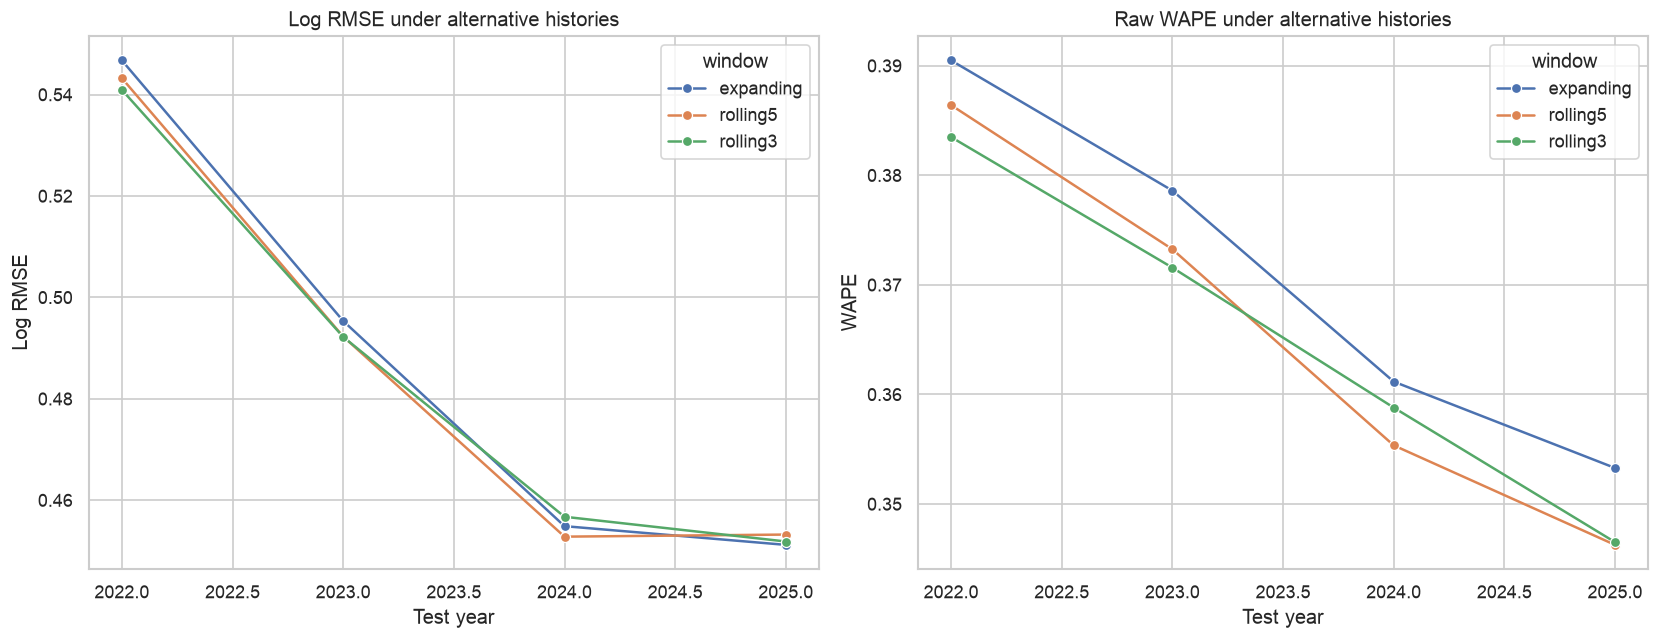

In [4]:
window_summary = window_metrics.groupby("window").agg(
    mean_rmse_log=("rmse_log", "mean"),
    mean_wape=("wape", "mean"),
    mean_spearman=("spearman", "mean"),
    mean_bias=("aggregate_bias", "mean"),
    worst_year_rmse=("rmse_log", "max"),
).reset_index().sort_values("mean_rmse_log")
window_summary.to_csv(OUT / "window_robustness_summary.csv", index=False)
display(window_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.lineplot(data=window_metrics, x="test_year", y="rmse_log", hue="window", marker="o", ax=axes[0])
axes[0].set(title="Log RMSE under alternative histories", xlabel="Test year", ylabel="Log RMSE")
sns.lineplot(data=window_metrics, x="test_year", y="wape", hue="window", marker="o", ax=axes[1])
axes[1].set(title="Raw WAPE under alternative histories", xlabel="Test year", ylabel="WAPE")
fig.tight_layout()
fig.savefig(OUT / "window_robustness.png", bbox_inches="tight")
plt.show()

## Economic feature-group experiments

Features are evaluated as economic families rather than selected solely through individual ridge coefficients. Two complementary experiments are used:

- **Add to auction core:** measure what each family contributes beyond auction history.
- **Drop from full model:** measure what the complete model loses without a family.

All transformed columns and missing indicators belonging to a source feature move together.

In [5]:
group_rows = []
auction_core = FEATURE_GROUPS["Auction history"]
group_specs = {"full_model": FEATURES, "auction_core_only": auction_core}
for group, group_features in FEATURE_GROUPS.items():
    if group != "Auction history":
        group_specs[f"auction_core_plus__{group}"] = list(dict.fromkeys(auction_core + group_features))
for group, group_features in FEATURE_GROUPS.items():
    group_specs[f"full_drop__{group}"] = [f for f in FEATURES if f not in set(group_features)]

for test_year, cache in expanding_cache.items():
    y_test = cache["test"]["auction_volume"].to_numpy(dtype=float)
    for specification, allowed_features in group_specs.items():
        mask = matrix_columns_for_sources(cache["prep"], allowed_features)
        pred_log, _ = fit_predict_log(
            cache["x_train"][:, mask], cache["y_train_log"],
            cache["x_test"][:, mask], cache["lambda"],
        )
        group_rows.append(metric_row(
            y_test, np.expm1(pred_log), test_year=test_year,
            specification=specification, feature_count=len(allowed_features),
        ))

group_metrics = pd.DataFrame(group_rows)
full_reference = group_metrics[group_metrics["specification"] == "full_model"][[
    "test_year", "rmse_log", "wape"
]].rename(columns={"rmse_log": "full_rmse_log", "wape": "full_wape"})
group_metrics = group_metrics.merge(full_reference, on="test_year")
group_metrics["rmse_delta_vs_full"] = group_metrics["rmse_log"] - group_metrics["full_rmse_log"]
group_metrics["wape_delta_vs_full"] = group_metrics["wape"] - group_metrics["full_wape"]
group_metrics.to_csv(OUT / "economic_feature_group_metrics.csv", index=False)

group_summary = group_metrics.groupby("specification").agg(
    feature_count=("feature_count", "first"),
    mean_rmse_log=("rmse_log", "mean"),
    mean_wape=("wape", "mean"),
    mean_rmse_delta_vs_full=("rmse_delta_vs_full", "mean"),
    mean_wape_delta_vs_full=("wape_delta_vs_full", "mean"),
).reset_index().sort_values("mean_rmse_log")
group_summary.to_csv(OUT / "economic_feature_group_summary.csv", index=False)
display(group_summary)

,specification,feature_count,mean_rmse_log,mean_wape,mean_rmse_delta_vs_full,mean_wape_delta_vs_full
15,full_drop__Size and history,89,0.4868,0.3700,-0.0002,-0.0009
14,full_drop__Security and corporate actions,95,0.4870,0.3708,-0.0000,-0.0001
13,full_drop__Sector state,91,0.4870,0.3709,-0.0000,0.0000
16,full_model,99,0.4870,0.3709,0.0000,0.0000
12,full_drop__Returns and price,88,0.4871,0.3709,0.0001,0.0000
11,full_drop__Market state,91,0.4874,0.3730,0.0004,0.0021
10,full_drop__Liquidity,83,0.4877,0.3690,0.0007,-0.0019
1,auction_core_plus__Calendar,42,0.4890,0.3714,0.0019,0.0005
2,auction_core_plus__Liquidity,35,0.5602,0.4205,0.0732,0.0496
9,full_drop__Calendar,76,0.5606,0.4213,0.0736,0.0504


## Alternative target formulations and weighting objectives

The same global feature matrix is used to isolate the effect of the modeling objective.

Target formulations:

- direct log auction level;
- deviation from the stock's trailing 20-auction median;
- auction volume relative to trailing ADV.

Weighting variants for the direct log target:

- uniform stock-days;
- stock-balanced weights;
- recent-data weights with a two-year half-life;
- greater weight on large auctions, capped to avoid domination by extremes.

In [6]:
objective_rows = []
for test_year, cache in expanding_cache.items():
    train, test = cache["train"], cache["test"]
    x_train, x_test = cache["x_train"], cache["x_test"]
    y_train_raw = train["auction_volume"].to_numpy(dtype=float)
    y_test_raw = test["auction_volume"].to_numpy(dtype=float)
    y_train_log = cache["y_train_log"]

    stock_counts = train.groupby("permno")["permno"].transform("size").to_numpy(dtype=float)
    stock_weights = 1 / stock_counts
    age_years = (pd.Timestamp(f"{test_year}-01-01") - pd.to_datetime(train["date"])).dt.days.to_numpy() / 365.25
    recent_weights = np.power(0.5, age_years / 2.0)
    target_median = np.median(y_train_raw)
    tail_weights = np.clip(np.sqrt((y_train_raw + 1) / (target_median + 1)), 0.5, 4.0)
    weight_specs = {
        "log_level_uniform": None,
        "log_level_stock_balanced": stock_weights,
        "log_level_recent_weighted": recent_weights,
        "log_level_large_auction_weighted": tail_weights,
    }
    for name, weights in weight_specs.items():
        pred_log, _ = fit_predict_log(
            x_train, y_train_log, x_test, cache["lambda"], weights=weights
        )
        objective_rows.append(metric_row(
            y_test_raw, np.expm1(pred_log), test_year=test_year, objective=name,
        ))

    global_median = np.median(y_train_raw)
    base_train_raw = train["median20_auction_volume"].fillna(global_median).to_numpy(dtype=float)
    base_test_raw = test["median20_auction_volume"].fillna(global_median).to_numpy(dtype=float)
    residual_target = y_train_log - np.log1p(base_train_raw)
    residual_pred, _ = fit_predict_log(
        x_train, residual_target, x_test, cache["lambda"]
    )
    residual_final_log = np.log1p(base_test_raw) + residual_pred
    lo, hi = np.quantile(y_train_log, [0.001, 0.999])
    objective_rows.append(metric_row(
        y_test_raw, np.expm1(np.clip(residual_final_log, lo, hi)),
        test_year=test_year, objective="median20_log_residual",
    ))

    train_adv = train["avg20_daily_volume"].to_numpy(dtype=float)
    test_adv = test["avg20_daily_volume"].to_numpy(dtype=float)
    fallback_adv = np.nanmedian(train_adv)
    train_adv = np.where(np.isfinite(train_adv) & (train_adv > 0), train_adv, fallback_adv)
    test_adv = np.where(np.isfinite(test_adv) & (test_adv > 0), test_adv, fallback_adv)
    intensity_target = np.log1p(y_train_raw / train_adv)
    intensity_pred, _ = fit_predict_log(
        x_train, intensity_target, x_test, cache["lambda"]
    )
    zlo, zhi = np.quantile(intensity_target, [0.001, 0.999])
    intensity_raw = np.expm1(np.clip(intensity_pred, zlo, zhi)) * test_adv
    objective_rows.append(metric_row(
        y_test_raw, intensity_raw, test_year=test_year, objective="log_auction_to_adv20",
    ))

objective_metrics = pd.DataFrame(objective_rows)
objective_metrics.to_csv(OUT / "objective_and_target_metrics.csv", index=False)
objective_summary = objective_metrics.groupby("objective").agg(
    mean_rmse_log=("rmse_log", "mean"), mean_wape=("wape", "mean"),
    mean_spearman=("spearman", "mean"), mean_bias=("aggregate_bias", "mean"),
    worst_rmse=("rmse_log", "max"),
).reset_index().sort_values("mean_rmse_log")
objective_summary.to_csv(OUT / "objective_and_target_summary.csv", index=False)
display(objective_summary)

,objective,mean_rmse_log,mean_wape,mean_spearman,mean_bias,worst_rmse
5,median20_log_residual,0.4794,0.3648,0.9556,-0.1224,0.5415
2,log_level_recent_weighted,0.4831,0.3678,0.9557,-0.1390,0.5419
4,log_level_uniform,0.4870,0.3709,0.9554,-0.1302,0.5467
3,log_level_stock_balanced,0.4922,0.3771,0.9546,-0.1168,0.5511
1,log_level_large_auction_weighted,0.5025,0.3824,0.9540,-0.0895,0.5709
0,log_auction_to_adv20,0.6318,0.3996,0.9459,-0.0366,0.7447


## Training-sample sensitivity and shuffled-target placebo

The 2025 expanding-window fold is re-estimated across three sample sizes and three random seeds. A shuffled-target model provides a negative control: if the pipeline still performed well after destroying the feature-target mapping, the evaluation would be suspect.

In [7]:
sample_rows = []
test_2025 = load_period("2025-01-01", "2026-01-01", 150_000, SEED + 900)
y_test_2025 = test_2025["auction_volume"].to_numpy(dtype=float)
selected_2025_lambda = expanding_cache[2025]["lambda"]

placebo_train = None
placebo_x_train = placebo_x_test = placebo_prep = None
for training_rows in [100_000, 350_000, 700_000]:
    for seed_offset in [11, 29, 47]:
        train = load_period("2015-01-01", "2025-01-01", training_rows, SEED + seed_offset)
        x_train, prep = fit_preprocessor(
            train, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        x_test = apply_preprocessor(
            test_2025, prep, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        pred_log, _ = fit_predict_log(
            x_train, train["log1p_auction_volume"].to_numpy(dtype=float),
            x_test, selected_2025_lambda,
        )
        sample_rows.append(metric_row(
            y_test_2025, np.expm1(pred_log), training_rows=training_rows,
            seed_offset=seed_offset, test_year=2025,
        ))
        if training_rows == 350_000 and seed_offset == 29:
            placebo_train, placebo_x_train, placebo_x_test, placebo_prep = train, x_train, x_test, prep

sample_sensitivity = pd.DataFrame(sample_rows)
sample_sensitivity.to_csv(OUT / "training_sample_sensitivity.csv", index=False)
sample_summary = sample_sensitivity.groupby("training_rows").agg(
    mean_rmse_log=("rmse_log", "mean"), std_rmse_log=("rmse_log", "std"),
    mean_wape=("wape", "mean"), std_wape=("wape", "std"),
).reset_index()
sample_summary.to_csv(OUT / "training_sample_sensitivity_summary.csv", index=False)
display(sample_summary)

rng = np.random.default_rng(SEED)
shuffled_target = rng.permutation(placebo_train["log1p_auction_volume"].to_numpy(dtype=float))
placebo_pred_log, _ = fit_predict_log(
    placebo_x_train, shuffled_target, placebo_x_test, selected_2025_lambda
)
placebo_metrics = pd.DataFrame([
    metric_row(y_test_2025, np.expm1(placebo_pred_log), model="shuffled_target_placebo", test_year=2025),
])
placebo_metrics.to_csv(OUT / "shuffled_target_placebo.csv", index=False)
display(placebo_metrics)

,training_rows,mean_rmse_log,std_rmse_log,mean_wape,std_wape
0,100000,0.4516,0.0007,0.3560,0.0017
1,350000,0.4509,0.0002,0.3565,0.0003
2,700000,0.4510,0.0003,0.3558,0.0004


,model,test_year,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
0,shuffled_target_placebo,2025,150000,"285,520.2894",0.8979,1.5156,1.8875,0.1033,-0.8569


## Coefficient signs and stability

Ridge coefficients are conditional associations, not causal effects. Correlated features may divide a common signal or reverse conditional signs. The appropriate review therefore combines:

- sign consistency across years and training windows;
- agreement with marginal rank relationships;
- a small set of economically pre-specified directions;
- feature-group ablation results.

In [8]:
main_coefficients = window_coefficients[
    (window_coefficients["output_feature"] == window_coefficients["source_feature"])
    & (window_coefficients["source_feature"] != "INTERCEPT")
].copy()
sign_summary = main_coefficients.groupby("source_feature").agg(
    estimates=("coefficient", "size"),
    positive_fraction=("coefficient", lambda s: (s > 0).mean()),
    negative_fraction=("coefficient", lambda s: (s < 0).mean()),
    mean_coefficient=("coefficient", "mean"),
    coefficient_std=("coefficient", "std"),
    min_coefficient=("coefficient", "min"),
    max_coefficient=("coefficient", "max"),
).reset_index().rename(columns={"source_feature": "feature"})
sign_summary["dominant_sign_fraction"] = sign_summary[["positive_fraction", "negative_fraction"]].max(axis=1)
sign_summary = sign_summary.merge(
    feature_validation[["variable", "group", "pooled_spearman", "within_stock_rank_corr"]],
    left_on="feature", right_on="variable", how="left"
).drop(columns="variable")
sign_summary["marginal_conditional_sign_agreement"] = (
    np.sign(sign_summary["mean_coefficient"]) == np.sign(sign_summary["pooled_spearman"])
)

expected_signs = {
    "lag1_auction_volume": (1, "Persistent auction demand"),
    "median20_auction_volume": (1, "Persistent normal auction level"),
    "avg20_auction_share": (1, "Higher historical closing participation"),
    "avg20_daily_volume": (1, "Greater underlying trading activity"),
    "quarterly_options_expiry": (1, "Known closing-volume event"),
    "monthly_options_expiry": (1, "Known closing-volume event"),
    "is_last_trading_day_month": (1, "Month-end rebalancing demand"),
    "is_early_close": (-1, "Short session and historically smaller auctions"),
}
sign_summary["expected_sign"] = sign_summary["feature"].map(
    lambda f: expected_signs.get(f, (np.nan, ""))[0]
)
sign_summary["economic_rationale"] = sign_summary["feature"].map(
    lambda f: expected_signs.get(f, (np.nan, ""))[1]
)
sign_summary["matches_expected_sign"] = np.where(
    sign_summary["expected_sign"].notna(),
    np.sign(sign_summary["mean_coefficient"]) == sign_summary["expected_sign"],
    np.nan,
)
sign_summary.to_csv(OUT / "coefficient_sign_stability.csv", index=False)
display(sign_summary[sign_summary["expected_sign"].notna()])
display(sign_summary.sort_values("dominant_sign_fraction").head(20))

,feature,estimates,positive_fraction,negative_fraction,mean_coefficient,coefficient_std,min_coefficient,max_coefficient,dominant_sign_fraction,group,pooled_spearman,within_stock_rank_corr,marginal_conditional_sign_agreement,expected_sign,economic_rationale,matches_expected_sign
7,avg20_auction_share,12,1.0000,0.0000,0.0382,0.0059,0.0265,0.0490,1.0000,Auction history,0.2251,0.3488,True,1.0000,Higher historical closing participation,1.0000
9,avg20_daily_volume,12,0.0000,1.0000,-0.2783,0.1411,-0.5272,-0.0049,1.0000,Liquidity,0.8318,0.4176,False,1.0000,Greater underlying trading activity,0.0000
21,is_early_close,12,0.0000,1.0000,-0.5653,0.1058,-0.6666,-0.3609,1.0000,Calendar,-0.0316,-0.0669,True,-1.0000,Short session and historically smaller auctions,1.0000
28,is_last_trading_day_month,12,1.0000,0.0000,0.7360,0.0335,0.6747,0.7756,1.0000,Calendar,0.0742,0.1449,True,1.0000,Month-end rebalancing demand,1.0000
36,lag1_auction_volume,12,1.0000,0.0000,0.3654,0.0667,0.2741,0.4629,1.0000,Auction history,0.8797,0.5574,True,1.0000,Persistent auction demand,1.0000
67,median20_auction_volume,12,1.0000,0.0000,0.2550,0.0192,0.2337,0.2947,1.0000,Auction history,0.9191,0.6580,True,1.0000,Persistent normal auction level,1.0000
72,monthly_options_expiry,12,1.0000,0.0000,0.2049,0.0259,0.1630,0.2490,1.0000,Calendar,0.0767,0.1525,True,1.0000,Known closing-volume event,1.0000
75,quarterly_options_expiry,12,1.0000,0.0000,1.6427,0.0404,1.5539,1.6842,1.0000,Calendar,0.1269,0.2495,True,1.0000,Known closing-volume event,1.0000


,feature,estimates,positive_fraction,negative_fraction,mean_coefficient,coefficient_std,min_coefficient,max_coefficient,dominant_sign_fraction,group,pooled_spearman,within_stock_rank_corr,marginal_conditional_sign_agreement,expected_sign,economic_rationale,matches_expected_sign
20,expiry_month_end_window,12,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Calendar,0.0070,0.0192,False,NaN,,NaN
52,lag1_quoted_spread,12,0.5000,0.5000,-0.0003,0.0053,-0.0114,0.0078,0.5000,Liquidity,-0.4034,-0.0302,True,NaN,,NaN
0,abnormal_volume_lag1,12,0.4167,0.5833,-0.0018,0.0111,-0.0146,0.0228,0.5833,Liquidity,0.1195,0.1178,False,NaN,,NaN
43,lag1_market_cap,12,0.4167,0.5833,-0.1769,0.3961,-0.6649,0.5303,0.5833,Size and history,0.6559,0.1998,False,NaN,,NaN
92,volatility60,12,0.5833,0.4167,-0.0002,0.0053,-0.0080,0.0108,0.5833,Returns and price,-0.1290,0.1438,True,NaN,,NaN
29,is_last_trading_day_quarter,12,0.4167,0.5833,-0.0020,0.0702,-0.0762,0.1580,0.5833,Calendar,0.0451,0.0872,False,NaN,,NaN
49,lag1_overnight_gap,12,0.4167,0.5833,-0.0009,0.0028,-0.0072,0.0032,0.5833,Returns and price,0.0033,0.0029,False,NaN,,NaN
26,is_last_5_trading_days_month,12,0.5833,0.4167,0.0055,0.0224,-0.0348,0.0385,0.5833,Calendar,0.0120,0.0220,True,NaN,,NaN
22,is_first_trading_day_month,12,0.5833,0.4167,0.0018,0.0140,-0.0198,0.0223,0.5833,Calendar,0.0028,0.0021,True,NaN,,NaN
56,lag1_sector_dollar_volume,12,0.5833,0.4167,0.0024,0.0055,-0.0064,0.0098,0.5833,Sector state,0.0471,0.2626,True,NaN,,NaN


## Residual calibration and extreme-auction diagnostics

These diagnostics reuse the fully out-of-time predictions from Notebook 07. They test calibration across prediction and actual-volume deciles, performance in the largest 1% of auctions, and persistent stock/date bias.

In [9]:
PREDICTION_GLOB = str(BASELINE_DIR / "predictions" / "out_of_time_predictions_*.parquet")
calibration_by_prediction = sql(f"""
WITH x AS (
    SELECT *, year(date) AS test_year,
           ntile(10) OVER (PARTITION BY year(date) ORDER BY global_ridge) AS prediction_decile
    FROM read_parquet('{PREDICTION_GLOB}')
)
SELECT test_year, prediction_decile, count(*) AS observations,
       avg(global_ridge) AS mean_prediction, avg(auction_volume) AS mean_actual,
       median(global_ridge) AS median_prediction, median(auction_volume) AS median_actual,
       avg(global_ridge) / nullif(avg(auction_volume), 0) AS mean_calibration_ratio,
       avg(abs(ln(1 + global_ridge) - log1p_auction_volume)) AS mae_log
FROM x GROUP BY test_year, prediction_decile ORDER BY test_year, prediction_decile
""")
calibration_by_prediction.to_csv(OUT / "calibration_by_prediction_decile.csv", index=False)

tail_diagnostics = sql(f"""
WITH x AS (
    SELECT *, year(date) AS test_year,
           percent_rank() OVER (PARTITION BY year(date) ORDER BY auction_volume) AS actual_percentile
    FROM read_parquet('{PREDICTION_GLOB}')
)
SELECT test_year,
       CASE WHEN actual_percentile >= 0.99 THEN 'top_1pct_actual' ELSE 'lower_99pct' END AS target_region,
       count(*) AS observations,
       avg(auction_volume) AS mean_actual, avg(global_ridge) AS mean_prediction,
       sum(abs(global_ridge - auction_volume)) / sum(auction_volume) AS wape,
       avg(abs(ln(1 + global_ridge) - log1p_auction_volume)) AS mae_log,
       sum(global_ridge) / sum(auction_volume) - 1 AS aggregate_bias
FROM x GROUP BY test_year, target_region ORDER BY test_year, target_region
""")
tail_diagnostics.to_csv(OUT / "extreme_auction_diagnostics.csv", index=False)

stock_bias = sql(f"""
SELECT permno, count(*) AS observations,
       avg(ln(1 + global_ridge) - log1p_auction_volume) AS mean_log_error,
       sum(global_ridge) / sum(auction_volume) - 1 AS aggregate_bias
FROM read_parquet('{PREDICTION_GLOB}')
GROUP BY permno HAVING count(*) >= 100
""")
stock_bias.to_csv(OUT / "persistent_stock_bias.csv", index=False)

display(calibration_by_prediction)
display(tail_diagnostics)
print("Stocks with >=100 test observations:", len(stock_bias))

,test_year,prediction_decile,observations,mean_prediction,mean_actual,median_prediction,median_actual,mean_calibration_ratio,mae_log
0,2022,1,32864,"2,193.5870","4,536.0244","1,628.8134","1,682.5000",0.4836,0.6229
1,2022,2,32864,"11,684.2096","16,537.4893","11,637.0055","11,339.0000",0.7065,0.3811
2,2022,3,32864,"23,133.0012","31,896.4501","23,078.9654","22,401.0000",0.7253,0.3484
3,2022,4,32864,"36,124.9433","45,361.7244","35,985.2427","34,807.5000",0.7964,0.3406
4,2022,5,32863,"52,656.2707","64,265.1170","52,364.3285","50,528.0000",0.8194,0.3372
5,2022,6,32863,"75,440.5986","93,256.4084","74,921.2391","71,693.0000",0.8090,0.3379
6,2022,7,32863,"109,383.6143","131,997.5655","108,871.7643","103,676.0000",0.8287,0.3349
7,2022,8,32863,"160,579.8406","192,161.5824","158,229.7115","151,220.0000",0.8357,0.3364
8,2022,9,32863,"276,972.6778","318,817.0279","270,432.0070","259,496.0000",0.8688,0.3333
9,2022,10,32863,"897,575.4410","1,047,297.5205","651,429.2106","657,508.0000",0.8570,0.3452


,test_year,target_region,observations,mean_actual,mean_prediction,wape,mae_log,aggregate_bias
0,2022,lower_99pct,325347,"152,821.0846","145,582.0428",0.3388,0.3659,-0.0474
1,2022,top_1pct_actual,3287,"4,330,935.6748","2,044,260.2300",0.5637,0.9565,-0.5280
2,2023,lower_99pct,315492,"174,514.2505","168,396.1603",0.3196,0.3346,-0.0351
3,2023,top_1pct_actual,3187,"4,752,853.4211","2,198,951.2078",0.5818,0.9173,-0.5373
4,2024,lower_99pct,313049,"208,382.2912","202,786.9018",0.3083,0.3189,-0.0269
5,2024,top_1pct_actual,3163,"5,297,291.9915","2,492,768.3133",0.5661,0.8204,-0.5294
6,2025,lower_99pct,304774,"262,986.1139","255,456.8749",0.3040,0.3147,-0.0286
7,2025,top_1pct_actual,3079,"5,691,810.6626","2,750,093.2053",0.5625,0.8236,-0.5168


Stocks with >=100 test observations: 1454


## Distribution drift

Population Stability Index (PSI) compares each test year's distribution with a historical training sample using training-defined decile bins. PSI is a screening statistic rather than a universal threshold; larger values indicate stronger distribution change.

In [10]:
DRIFT_FEATURES = [
    "log1p_auction_volume", "median20_auction_volume", "avg20_daily_volume",
    "lag1_market_cap", "avg20_auction_share", "auction_cv20",
    "volatility20", "market_volatility20", "prior_auction_observations",
]

def psi(train_values, test_values):
    train_values = np.asarray(train_values, dtype=float)
    test_values = np.asarray(test_values, dtype=float)
    train_finite = train_values[np.isfinite(train_values)]
    if len(train_finite) < 100:
        return np.nan
    edges = np.unique(np.quantile(train_finite, np.linspace(0, 1, 11)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    train_hist = np.histogram(train_values[np.isfinite(train_values)], bins=edges)[0].astype(float)
    test_hist = np.histogram(test_values[np.isfinite(test_values)], bins=edges)[0].astype(float)
    train_missing = np.sum(~np.isfinite(train_values))
    test_missing = np.sum(~np.isfinite(test_values))
    train_dist = np.append(train_hist, train_missing) / len(train_values)
    test_dist = np.append(test_hist, test_missing) / len(test_values)
    train_dist = np.clip(train_dist, 1e-6, None)
    test_dist = np.clip(test_dist, 1e-6, None)
    return np.sum((test_dist - train_dist) * np.log(test_dist / train_dist))

drift_rows = []
for test_year, cache in expanding_cache.items():
    for feature in DRIFT_FEATURES:
        drift_rows.append({
            "test_year": test_year, "feature": feature,
            "psi": psi(
                pd.to_numeric(cache["train"][feature], errors="coerce"),
                pd.to_numeric(cache["test"][feature], errors="coerce"),
            ),
        })
drift = pd.DataFrame(drift_rows)
drift.to_csv(OUT / "distribution_drift_psi.csv", index=False)
display(drift.pivot(index="feature", columns="test_year", values="psi"))

test_year,2022,2023,2024,2025
feature,,,,
auction_cv20,0.1848,0.2525,0.2896,0.2607
avg20_auction_share,0.2854,0.6028,1.0672,0.9372
avg20_daily_volume,0.0038,0.0014,0.0043,0.0402
lag1_market_cap,0.0094,0.0139,0.0262,0.0279
log1p_auction_volume,0.0529,0.0963,0.1602,0.2644
market_volatility20,5.3409,2.9159,2.8081,0.8271
median20_auction_volume,0.0635,0.1162,0.1914,0.3145
prior_auction_observations,1.8721,1.8820,1.8554,1.8045
volatility20,0.3108,0.0297,0.0110,0.0544


## Visual audit summary

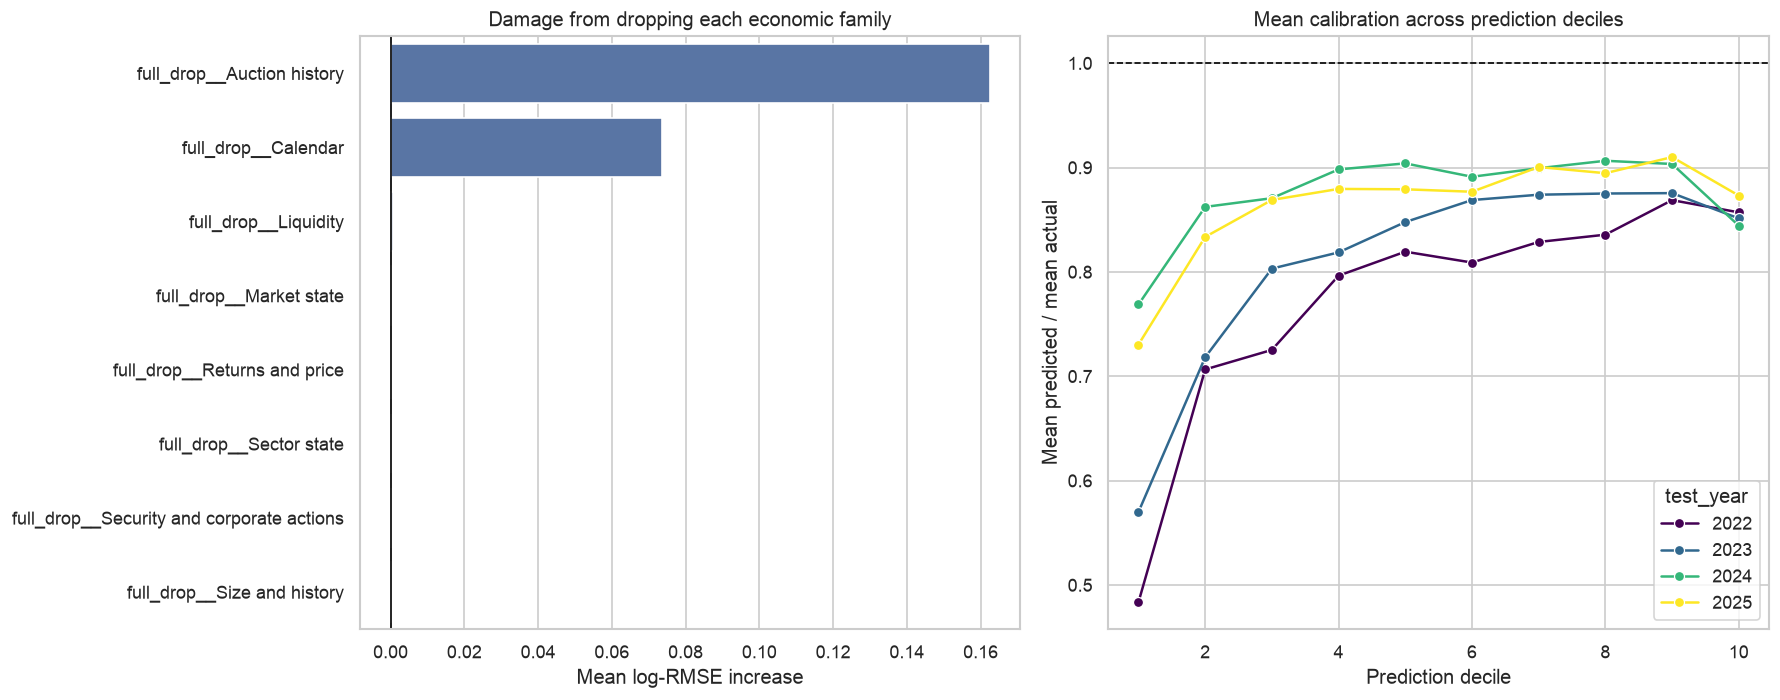

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_drop = group_summary[group_summary["specification"].str.startswith("full_drop")].sort_values(
    "mean_rmse_delta_vs_full", ascending=False
)
sns.barplot(data=top_drop, y="specification", x="mean_rmse_delta_vs_full", ax=axes[0], color="#4c72b0")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set(title="Damage from dropping each economic family", xlabel="Mean log-RMSE increase", ylabel="")

sns.lineplot(data=calibration_by_prediction, x="prediction_decile", y="mean_calibration_ratio",
             hue="test_year", marker="o", ax=axes[1], palette="viridis")
axes[1].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1].set(title="Mean calibration across prediction deciles", xlabel="Prediction decile",
            ylabel="Mean predicted / mean actual")
fig.tight_layout()
fig.savefig(OUT / "global_specification_summary.png", bbox_inches="tight")
plt.show()

## Handoff criteria

Separate-model experiments should begin only if:

- global performance remains credible across reasonable windows, penalties, and samples;
- the shuffled-target placebo collapses as expected;
- feature-group conclusions have economic coherence;
- coefficient signs are interpreted jointly with collinearity and ablations;
- remaining failures are concentrated in identifiable regimes rather than caused by an unstable global specification.

In [12]:
artifacts = [
    "window_robustness_summary.csv", "nested_lambda_validation.csv",
    "economic_feature_group_summary.csv", "objective_and_target_summary.csv",
    "training_sample_sensitivity_summary.csv", "shuffled_target_placebo.csv",
    "coefficient_sign_stability.csv", "calibration_by_prediction_decile.csv",
    "extreme_auction_diagnostics.csv", "persistent_stock_bias.csv",
    "distribution_drift_psi.csv",
]
manifest = pd.DataFrame({"artifact": artifacts, "path": [str(OUT / x) for x in artifacts]})
manifest.to_csv(OUT / "artifact_manifest.csv", index=False)
display(manifest)

,artifact,path
0,window_robustness_summary.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
1,nested_lambda_validation.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
2,economic_feature_group_summary.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
3,objective_and_target_summary.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
4,training_sample_sensitivity_summary.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
5,shuffled_target_placebo.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
6,coefficient_sign_stability.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
7,calibration_by_prediction_decile.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
8,extreme_auction_diagnostics.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
9,persistent_stock_bias.csv,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
